# 04 - Preprocessing and PCA

1. Clean the cube: **mask** bad pixels and **remove** unreliable bands.
2. **Normalise** every band.
3. Compress the ~170 remaining bands into a few **principal components** with `IncrementalPCA`.
4. Look at the **explained variance** and decide how many components to keep.
5. **Save** the whole preprocessing + PCA as one file, so the API can repeat exactly the same transform later.

**Requires:** notebooks 02 and 03 have been run, so `data/mock/mock_cube.h5` exists.

## 1. The pipeline and why the order matters

```
cube (H, W, 200)
  -> valid-pixel mask        which pixels can we trust at all?
  -> drop unreliable bands   (200 -> ~166)
  -> normalise each band     mean 0, std 1
  -> PCA                     (166 -> K components)
  -> scores (H, W, K)        what the model will see
```

Two rules we follow from the start:

- **Everything we learn from the data is stored**: which bands were kept, each band's mean and std, and the PCA matrix. A new scene must be transformed with **these** numbers, never with numbers recomputed from the new scene.
- **PCA is fitted on valid pixels only.** Missing or broken pixels would distort the result.

(One caution for later: when we train and test models, the mean/std/PCA must be fitted on the **training area only**, to avoid leaking information from the test area. Today the cube is a clean mock and PCA does not use labels, so we fit on all valid pixels.)

## 2. Imports and load the cube

In [10]:
from pathlib import Path

import h5py
import joblib
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import IncrementalPCA

plt.rcParams["figure.dpi"] = 110

REPO_ROOT = Path(".") if Path("notebooks").is_dir() else Path("..")
MOCK_DIR = REPO_ROOT / "data" / "mock"
PROC_DIR = REPO_ROOT / "data" / "processed"
MODEL_DIR = REPO_ROOT / "models"
FIG_DIR = REPO_ROOT / "reports" / "figures"
for d in (PROC_DIR, MODEL_DIR, FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)


def save_fig(fig, name):
    fig.savefig(FIG_DIR / name, dpi=150, bbox_inches="tight")
    print("saved", FIG_DIR / name)


h5_path = MOCK_DIR / "mock_cube.h5"
assert h5_path.exists(), "run notebooks 02 and 03 first to create the mock cube"

with h5py.File(h5_path, "r") as f:
    cube = f["cube"][...]                    # (H, W, B) float32
    labels = f["labels"][...]                # (H, W) uint8, 1 = stressed
    wavelengths = f["wavelengths_nm"][...]   # (B,) nm

H, W, B = cube.shape
print("cube:", cube.shape, cube.dtype, "| labels:", labels.shape, "| stressed pixels:", int(labels.sum()))

cube: (67, 67, 200) float32 | labels: (67, 67) | stressed pixels: 21


## 3. Remove unreliable bands

Real satellite data has bands we should not trust:

- **Water-vapour absorption** (~1340-1460 nm and ~1790-1960 nm): the atmosphere absorbs almost all light there, so these bands are mostly noise. This is exactly what was removed from Indian Pines to get from 220 to 200 bands.
- **Sensor edges** (below ~420 nm and above ~2450 nm): usually noisy.

Our mock cube is cleaner than real data, but we practise the real workflow. The red dots show which bands are dropped.

kept 166 of 200 bands, removed 34


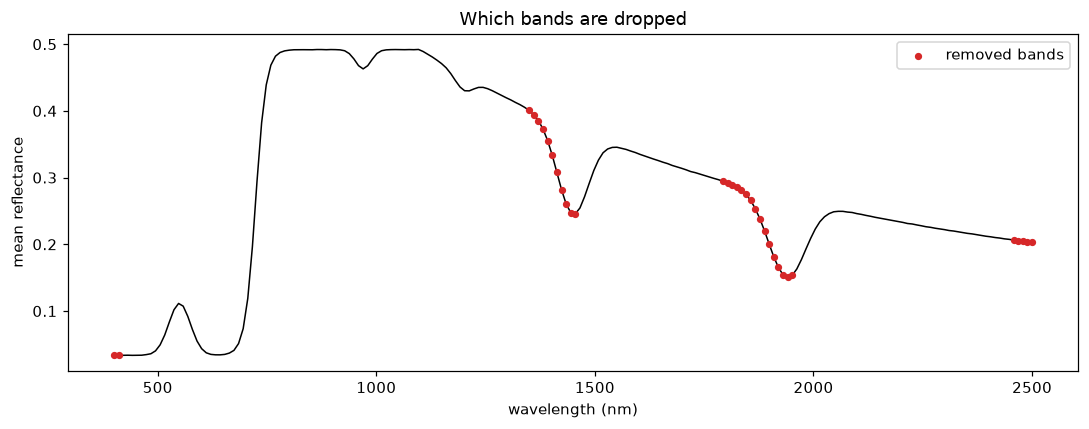

In [11]:
BAD_RANGES_NM = [(1340, 1460), (1790, 1960)]   # strong water-vapour absorption
EDGE_NM = (420, 2450)                           # noisy ends of the sensor range


def keep_band_mask(wavelengths):
    keep = (wavelengths >= EDGE_NM[0]) & (wavelengths <= EDGE_NM[1])
    for lo, hi in BAD_RANGES_NM:
        keep &= ~((wavelengths >= lo) & (wavelengths <= hi))
    return keep


keep = keep_band_mask(wavelengths)
print(f"kept {keep.sum()} of {B} bands, removed {(~keep).sum()}")

mean_spectrum = cube.reshape(-1, B).mean(axis=0)
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(wavelengths, mean_spectrum, color="black", lw=1)
ax.scatter(wavelengths[~keep], mean_spectrum[~keep], color="tab:red", s=14, label="removed bands", zorder=3)
ax.set_xlabel("wavelength (nm)")
ax.set_ylabel("mean reflectance")
ax.set_title("Which bands are dropped")
ax.legend()
fig.tight_layout()
plt.show()

## 4. The valid-pixel mask

A pixel is **valid** only if **all** its values are finite numbers (no `NaN`/`inf`), inside the physical reflectance range 0 to 1, and not completely zero (a dead pixel). Clouds, sensor gaps and corrupted tiles show up as exactly these problems.

Our mock cube has no bad pixels, so a mask that finds nothing would prove nothing. We **damage a copy** on purpose and check the mask catches every problem we planted.

In [12]:
def make_valid_mask(cube):
    finite = np.isfinite(cube).all(axis=-1)
    in_range = ((cube >= 0) & (cube <= 1)).all(axis=-1)    # comparisons with NaN are False, so NaN fails too
    not_blank = cube.sum(axis=-1) > 0                      # a dead (all-zero) pixel fails here
    return finite & in_range & not_blank


# our real cube: everything should be valid
print("valid pixels in the real cube:", int(make_valid_mask(cube).sum()), "of", H * W)

# a damaged COPY, to test the mask
damaged = cube.copy()
damaged[5:8, 50:53, :] = np.nan      # a 3 x 3 patch of missing data ("cloud") -> 9 pixels
damaged[60, 10, :] = 0               # one dead pixel -> 1 pixel
damaged[20, 20, 100] = 5.0           # one impossible reflectance value -> 1 pixel

bad = ~make_valid_mask(damaged)
print("bad pixels found in the damaged copy:", int(bad.sum()), "(planted: 9 + 1 + 1 = 11)")

valid pixels in the real cube: 4489 of 4489
bad pixels found in the damaged copy: 11 (planted: 9 + 1 + 1 = 11)


## 5. Normalise and fit the preprocessing

**Per-band standardisation:** for each band, subtract its mean and divide by its standard deviation, so every band has mean 0 and std 1. Without this, bands with large reflectance (the NIR plateau) would dominate PCA and neural networks just because their numbers are bigger.

We keep everything in one dictionary, the **bundle**. It holds the kept bands, the means, the stds and the fitted PCA.

**IncrementalPCA** learns the principal components from the data **in small batches** (`partial_fit`) instead of all at once. For this tiny mock cube that is not needed, but real scenes will not fit in memory, and then the same loop reads one chunk of the HDF5 file at a time. A batch must contain at least as many pixels as components.

The three functions below are the whole pipeline. `fit_preprocessing` learns from a cube; `apply_preprocessing` applies what was learned to any cube, today's or tomorrow's.

In [13]:
def standardise(cube, bundle):
    # valid pixels only, kept bands only, normalised with the STORED mean/std
    valid = make_valid_mask(cube)
    X = cube[valid][:, bundle["keep_bands"]]
    Z = (X - bundle["mean"]) / bundle["std"]
    return Z.astype(np.float32), valid


def fit_preprocessing(cube, wavelengths, n_components, batch_size=500):
    valid = make_valid_mask(cube)
    keep = keep_band_mask(wavelengths)
    X = cube[valid][:, keep].astype(np.float64)

    bundle = {
        "keep_bands": keep,
        "wavelengths": wavelengths[keep],
        "mean": X.mean(axis=0),
        "std": X.std(axis=0) + 1e-8,          # tiny constant avoids division by zero
        "n_components": n_components,
    }

    Z, _ = standardise(cube, bundle)
    ipca = IncrementalPCA(n_components=n_components, batch_size=batch_size)
    for start in range(0, len(Z), batch_size):
        batch = Z[start:start + batch_size]
        if len(batch) >= n_components:          # partial_fit needs at least n_components rows
            ipca.partial_fit(batch)
    bundle["pca"] = ipca
    return bundle


def apply_preprocessing(cube, bundle):
    Z, valid = standardise(cube, bundle)
    scores = np.zeros((*cube.shape[:2], bundle["n_components"]), dtype=np.float32)   # invalid pixels stay 0
    scores[valid] = bundle["pca"].transform(Z)
    return scores, valid

## 6. How many components? Fit and look at the scree plot

`N_COMPONENTS` is a **design choice**, so we look at the data first. To see the whole picture we compute the **exact** eigenvalues of the covariance matrix (cheap here: only ~166 x 166). Each eigenvalue is the variance of one principal component.

Two lines are marked on the plots: the number of components we keep, and the 99% mark. For Indian Pines (notebook 01), 25 components reached 99%. Check what happens with our mock cube.

standardised: (4489, 166) float32
per-band mean, largest |value|: 2.7193207685627385e-08
per-band std, min / max       : 0.9999988079071045 / 0.9999995231628418

IncrementalPCA vs exact, largest difference in explained variance: 0.0005
variance kept by our 10 components: 62.4%
components needed for 99% of the variance: 155 of 166
saved ..\reports\figures\pca_scree.png


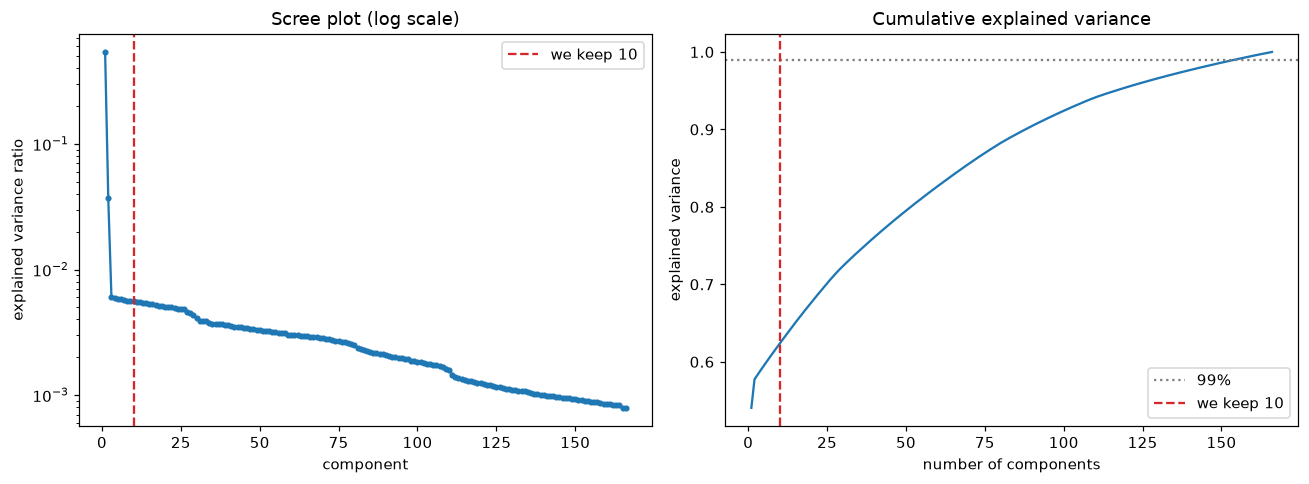

In [14]:
N_COMPONENTS = 10

bundle = fit_preprocessing(cube, wavelengths, N_COMPONENTS)
Z, valid = standardise(cube, bundle)
print("standardised:", Z.shape, Z.dtype)
print("per-band mean, largest |value|:", float(np.abs(Z.mean(axis=0)).max()))
print("per-band std, min / max       :", float(Z.std(axis=0).min()), "/", float(Z.std(axis=0).max()))

# exact eigenvalues of the covariance matrix = variance of every principal component
eigvals = np.linalg.eigvalsh(np.cov(Z.astype(np.float64), rowvar=False))[::-1]
evr = eigvals / eigvals.sum()
cum = np.cumsum(evr)
n99 = int(np.searchsorted(cum, 0.99) + 1)

diff = np.abs(bundle["pca"].explained_variance_ratio_ - evr[:N_COMPONENTS]).max()
print()
print(f"IncrementalPCA vs exact, largest difference in explained variance: {diff:.4f}")
print(f"variance kept by our {N_COMPONENTS} components: {cum[N_COMPONENTS - 1]:.1%}")
print(f"components needed for 99% of the variance: {n99} of {len(evr)}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
x = np.arange(1, len(evr) + 1)

axes[0].semilogy(x, evr, marker="o", ms=3)
axes[0].axvline(N_COMPONENTS, color="tab:red", ls="--", label=f"we keep {N_COMPONENTS}")
axes[0].set_title("Scree plot (log scale)")
axes[0].set_xlabel("component")
axes[0].set_ylabel("explained variance ratio")
axes[0].legend()

axes[1].plot(x, cum)
axes[1].axhline(0.99, color="gray", ls=":", label="99%")
axes[1].axvline(N_COMPONENTS, color="tab:red", ls="--", label=f"we keep {N_COMPONENTS}")
axes[1].set_title("Cumulative explained variance")
axes[1].set_xlabel("number of components")
axes[1].set_ylabel("explained variance")
axes[1].legend()

fig.tight_layout()
save_fig(fig, "pca_scree.png")
plt.show()

### Reading the scree plot

- The curve drops steeply after the **first two components**, then turns into a long, slowly sloping tail with no further cliff. The first two carry the real signal (brightness variation and the stress pattern). The tail is the **noise floor**: we added independent random noise to every band, and no projection can compress noise like that.
- That is why the 99% rule does not work here: it asks for far more components than carry any signal. Indian Pines behaves differently because real neighbouring bands are strongly correlated.
- So `N_COMPONENTS` is chosen by judgement, not by the 99% rule. We keep **10**: more than the 2 to 3 signal components, so the 3D-CNN still has a spectral axis to convolve along, but still small. Components 3 to 10 are mostly noise; the model will learn to ignore them.
- With the real potato data, repeat this step: the scree plot there will decide.

## 7. Do the components separate healthy from stressed?

PCA never saw the labels, so this is a fair test. We apply the saved bundle to the cube, show the first three component images, plot the first two components against each other, and measure for each component how far apart the healthy and stressed averages are, in units of their spread (`d`; above about 1 means clearly separated).

scores: (67, 67, 10) float32 | valid pixels: 4489

PC1: separation d = 4.92
PC2: separation d = 7.90
PC3: separation d = 0.11
PC4: separation d = 0.19
PC5: separation d = 0.01
PC6: separation d = 0.10
saved ..\reports\figures\pca_components.png


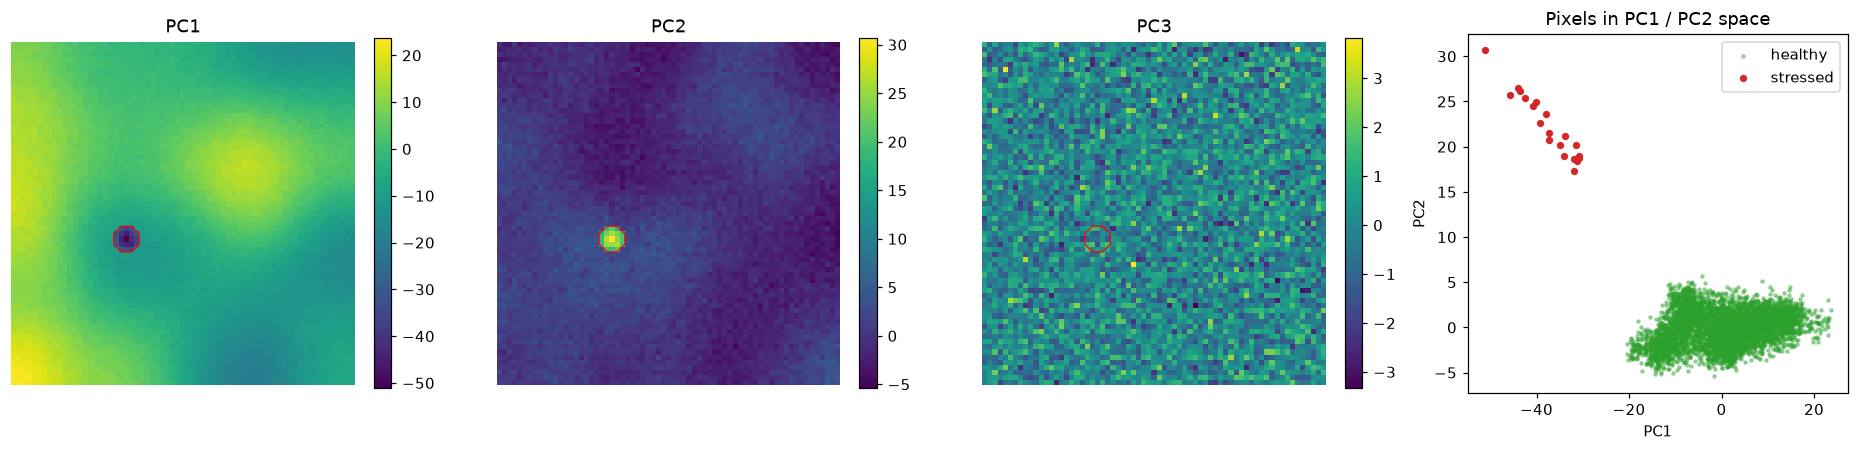

In [15]:
scores, valid = apply_preprocessing(cube, bundle)
print("scores:", scores.shape, scores.dtype, "| valid pixels:", int(valid.sum()))

healthy = (labels == 0) & valid
stressed = (labels == 1) & valid
print()
for k in range(6):
    a, b = scores[healthy, k], scores[stressed, k]
    d = abs(a.mean() - b.mean()) / np.sqrt((a.var() + b.var()) / 2)
    print(f"PC{k + 1}: separation d = {d:.2f}")

fig, axes = plt.subplots(1, 4, figsize=(17, 4.2))
for k in range(3):
    im = axes[k].imshow(scores[:, :, k], cmap="viridis")
    axes[k].contour(labels, levels=[0.5], colors="red", linewidths=0.8)
    axes[k].set_title(f"PC{k + 1}")
    axes[k].axis("off")
    fig.colorbar(im, ax=axes[k], fraction=0.046)

axes[3].scatter(scores[healthy, 0], scores[healthy, 1], s=4, color="tab:green", alpha=0.4, label="healthy")
axes[3].scatter(scores[stressed, 0], scores[stressed, 1], s=14, color="tab:red", label="stressed")
axes[3].set_xlabel("PC1")
axes[3].set_ylabel("PC2")
axes[3].set_title("Pixels in PC1 / PC2 space")
axes[3].legend()

fig.tight_layout()
save_fig(fig, "pca_components.png")
plt.show()

### What to notice

- **PC1** is mostly the smooth, large-scale variation across the field (light and background vigour), and the stressed patch sits at its low end.
- **PC2** is almost only the patch: this is the stress signal on its own.
- **PC3** is pure noise (no structure, separation near 0). This matches the scree plot: two signal components, then noise.
- In the scatter plot the stressed pixels sit well away from the healthy cloud, even though PCA never saw a label.

## 8. Save the bundle and test the reload

Two files:

- `models/pca_preprocess.joblib`: the whole bundle (kept bands, means, stds, PCA). This is what the API will load.
- `data/processed/mock_pca.npz`: the reduced cube `(H, W, K)`, labels and mask, ready for model training.

A saved model that has never been loaded back is untested. So we reload the bundle and check it gives **identical** scores, then apply it to the damaged copy to check the mask works end to end: broken pixels must come out as zeros, never as `NaN`.

(`joblib` files are Python pickles: only load files you created yourself or trust.)

In [16]:
bundle_path = MODEL_DIR / "pca_preprocess.joblib"
joblib.dump(bundle, bundle_path)

np.savez_compressed(
    PROC_DIR / "mock_pca.npz",
    scores=scores, labels=labels, valid=valid, wavelengths_kept=bundle["wavelengths"],
)
print(f"{bundle_path.name}: {bundle_path.stat().st_size / 1e3:.0f} KB")
print(f"mock_pca.npz: {(PROC_DIR / 'mock_pca.npz').stat().st_size / 1e3:.0f} KB")

# reload test 1: same input -> same output
loaded = joblib.load(bundle_path)
scores_again, _ = apply_preprocessing(cube, loaded)
print()
print("identical scores after reload:", np.allclose(scores, scores_again))

# reload test 2: the damaged copy goes through the same bundle
scores_damaged, valid_damaged = apply_preprocessing(damaged, loaded)
print("NaN in output of damaged copy:", bool(np.isnan(scores_damaged).any()))
print("pixels set to zero by the mask:", int((~valid_damaged).sum()), "(expected 11)")
print("zero pixels in output        :", int((scores_damaged == 0).all(axis=-1).sum()))

pca_preprocess.joblib: 21 KB
mock_pca.npz: 169 KB

identical scores after reload: True
NaN in output of damaged copy: False
pixels set to zero by the mask: 11 (expected 11)
zero pixels in output        : 11


## Takeaways

- Order: **mask -> drop bands -> normalise -> PCA**, and store everything learned in one **bundle**.
- Test a mask on a **deliberately damaged copy**, otherwise you only know it finds nothing in clean data.
- **IncrementalPCA** learns in batches, so it also works when the data does not fit in memory.
- Choose the number of components from the **scree plot**. The 99% rule is not universal: it needs correlated bands. With white noise in every band it asks for far too many components.
- Always **reload what you saved** and compare.

**Next:** PyTorch basics (Dataset, DataLoader, training loop).